# Interview Analysis Visualizations

Three key visualizations showcasing the pipeline results.

In [4]:
from pathlib import Path as FilePath
from collections import Counter, defaultdict
import json
import re

with open('output/stage_1/aggregate_data.json', 'r', encoding='utf-8') as f:
    agg_data = json.load(f)

with open('output/stage_1/aggregate_report.md', 'r', encoding='utf-8') as f:
    aggregate_report = f.read()

with open('outputs/stage_2/pattern_findings.json', 'r', encoding='utf-8') as f:
    findings_data = json.load(f)

# IDs follow the sorted transcript-file order used by README.rd.
BSC_INTERVIEWS = ['I01', 'I07', 'I08', 'I09', 'I10', 'I11', 'I12']
MSC_INTERVIEWS = ['I02', 'I03', 'I04', 'I05', 'I06', 'I13', 'I14', 'I15', 'I16', 'I17']
TRANSCRIPT_DIR = FilePath('transcription/test')
transcript_files = sorted(TRANSCRIPT_DIR.glob('*.txt'))
interview_ids = [f'I{i:02d}' for i in range(1, len(transcript_files) + 1)]
assert interview_ids == agg_data['included_interviews'], 'Transcript order does not match aggregate interview IDs.'
assert set(BSC_INTERVIEWS).isdisjoint(MSC_INTERVIEWS)
assert set(BSC_INTERVIEWS + MSC_INTERVIEWS) == set(interview_ids)

student_counts = {}
for interview_id, transcript_path in zip(interview_ids, transcript_files):
    header = transcript_path.read_text(encoding='utf-8').splitlines()[0]
    student_numbers = set(re.findall(r'\bStudent\s+(\d+)\s*:', header, flags=re.IGNORECASE))
    assert student_numbers, f'No student roster found in {transcript_path.name}.'
    student_counts[interview_id] = len(student_numbers)

total_students = sum(student_counts.values())
bsc_student_total = sum(student_counts[i] for i in BSC_INTERVIEWS)
msc_student_total = sum(student_counts[i] for i in MSC_INTERVIEWS)
print(f'Total students across all interviews: {total_students}')
for interview_id in interview_ids:
    print(f'{interview_id}: {student_counts[interview_id]} students')
print(f'BSc students: {bsc_student_total}; MSc students: {msc_student_total}')

report_total_match = re.search(r'Total quotes across all interviews:\*\*\s*(\d+)', aggregate_report)
assert report_total_match, 'Could not read the total quote count from aggregate_report.md.'
report_quote_total = int(report_total_match.group(1))
codebook_quote_counts = {
    code: sum(interview_counts.values())
    for code, interview_counts in agg_data['code_interview_matrix'].items()
}
matrix_quote_total = sum(codebook_quote_counts.values())
pass2_quote_lookup = {}
for interview_id in interview_ids:
    pass2_path = FilePath('output/stage_1') / interview_id / 'pass2.json'
    pass2 = json.loads(pass2_path.read_text(encoding='utf-8'))
    for quote in pass2['interpretations']:
        pass2_quote_lookup[quote['quote_id']] = (quote['code'], quote['cited_text'])
pass2_quote_total = len(pass2_quote_lookup)
assert matrix_quote_total == report_quote_total == pass2_quote_total, (
    f'Quote totals differ: report={report_quote_total}, matrix={matrix_quote_total}, pass2={pass2_quote_total}'
)
print(f'Total coded quotes: {pass2_quote_total} (matches aggregate_report.md)')

finding_keys = [f'F{i:02d}' for i in range(1, len(findings_data['findings']) + 1)]
finding_theme_counts = {}
finding_quote_counts = {}
code_finding_counts = Counter()
cited_quote_ids = set()
all_finding_quote_ids = []
for finding_key, finding in zip(finding_keys, findings_data['findings']):
    printed_quotes = finding.get('quotes', [])
    quote_ids = [quote['quote_id'] for quote in printed_quotes]
    assert len(quote_ids) == len(set(quote_ids)), f'Duplicate quote within {finding_key}.'
    assert set(quote_ids) == set(finding.get('quote_ids', [])), f'Printed quotes and quote_ids differ in {finding_key}.'

    theme_counts = Counter()
    for quote in printed_quotes:
        quote_id = quote['quote_id']
        assert quote_id in pass2_quote_lookup, f'{quote_id} is not in Stage 1 pass2.'
        actual_code, actual_text = pass2_quote_lookup[quote_id]
        assert quote['code'] == actual_code and quote['cited_text'] == actual_text, (
            f'Stage 2 citation differs from Stage 1 for {quote_id}.'
        )
        theme_counts[actual_code.split('.')[0]] += 1
        code_finding_counts[(actual_code, finding_key)] += 1
        cited_quote_ids.add(quote_id)
        all_finding_quote_ids.append(quote_id)

    finding_theme_counts[finding_key] = theme_counts
    finding_quote_counts[finding_key] = len(printed_quotes)
    assert sum(theme_counts.values()) == finding_quote_counts[finding_key]

cited_reference_total = len(all_finding_quote_ids)
unique_cited_quote_total = len(cited_quote_ids)
assert sum(code_finding_counts.values()) == cited_reference_total
assert unique_cited_quote_total <= cited_reference_total <= pass2_quote_total
print(
    f'Stage 2 citations: {cited_reference_total} quote references, '
    f'{unique_cited_quote_total} unique quotes from {pass2_quote_total} coded quotes.'
)
print('Cited quote references by theme:', dict(sorted(Counter(
    theme for counts in finding_theme_counts.values() for theme, count in counts.items()
    for _ in range(count)
).items())))
print('Theme counts per finding:')
for finding_key, finding in zip(finding_keys, findings_data['findings']):
    print(f'  {finding_key} {finding["title"]}: {dict(sorted(finding_theme_counts[finding_key].items()))} (n={finding_quote_counts[finding_key]})')

Total students across all interviews: 52
I01: 3 students
I02: 1 students
I03: 5 students
I04: 4 students
I05: 2 students
I06: 4 students
I07: 3 students
I08: 3 students
I09: 2 students
I10: 3 students
I11: 2 students
I12: 3 students
I13: 3 students
I14: 3 students
I15: 4 students
I16: 4 students
I17: 3 students
BSc students: 19; MSc students: 33
Total coded quotes: 503 (matches aggregate_report.md)
Stage 2 citations: 96 quote references, 87 unique quotes from 503 coded quotes.
Cited quote references by theme: {'1': 48, '2': 22, '3': 26}
Theme counts per finding:
  F01 Equipment/calibration troubleshooting as a universal problem-solving experience: {'1': 12, '3': 2} (n=14)
  F02 Positive framing of collaborative discussion as the mechanism of understanding: {'1': 7, '2': 1, '3': 3} (n=11)
  F03 Freedom/openness of exploration valued but also source of frustration: {'1': 5, '2': 4, '3': 3} (n=12)
  F04 Direct disagreement on whether labs are worth doing if not calibrated/theory-aligned t

In [ ]:
import textwrap
from itertools import combinations
from collections import defaultdict

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.path import Path
import seaborn as sns
import networkx as nx
import plotly.graph_objects as go
import plotly.express as px

with open('outputs/stage_2/pattern_findings.json', 'r', encoding='utf-8') as f:
    findings_data = json.load(f)

with open('codebook.yaml', 'r', encoding='utf-8') as f:
    codebook = yaml.safe_load(f)

# Stage 1 aggregate data also supplies duplicate-citation information below.
report_data = agg_data

In [9]:
# finding_interview_edges and finding_info for network graph
finding_interview_edges = defaultdict(lambda: defaultdict(int))
finding_info = {}

for finding in findings_data['findings']:
    finding_type = finding['finding_type']
    title = finding['title'][:50] + '...' if len(finding['title']) > 50 else finding['title']
    confidence = finding.get('confidence', 'moderate')

    interviews_cited = set()
    for quote_id in finding['quote_ids']:
        interview_id = quote_id.split('-')[0]
        interviews_cited.add(interview_id)
        finding_interview_edges[finding_type][interview_id] += 1

    finding_info[finding_type] = {
        'title': title,
        'confidence': confidence,
        'full_title': finding['title'],
        'interviews': interviews_cited,
        'quote_count': len(finding['quote_ids'])
    }


def find_key(obj, key):
    """Return the first value stored under `key` anywhere inside a nested dict/list."""
    if isinstance(obj, dict):
        if key in obj:
            return obj[key]
        for v in obj.values():
            r = find_key(v, key)
            if r is not None:
                return r
    elif isinstance(obj, list):
        for v in obj:
            r = find_key(v, key)
            if r is not None:
                return r
    return None


def walk_dicts(obj):
    if isinstance(obj, dict):
        yield obj
        for v in obj.values():
            yield from walk_dicts(v)
    elif isinstance(obj, list):
        for v in obj:
            yield from walk_dicts(v)


# ------------------------------------------------------------------
# Code → theme mapping
#   1) from the codebook (any nesting depth: any dict that has a 'codes' entry)
#   2) any code seen elsewhere in the data but missing from the codebook is
#      assigned to its theme by its prefix ("2.c" -> theme "2")
# ------------------------------------------------------------------
code_to_theme = {}     # {code_id: (theme_id, theme_name)}
theme_names = {}       # {theme_id: theme_name}
theme_ids = []


def add_theme(tid, name=''):
    tid = str(tid)
    if tid not in theme_ids:
        theme_ids.append(tid)
    if name and not theme_names.get(tid):
        theme_names[tid] = name
    theme_names.setdefault(tid, '')
    return tid


for key, node in codebook.items():
    if isinstance(node, dict) and 'codes' in node:
        tid = add_theme(key, node.get('name', ''))
        codes = node['codes']
        for c in (codes.keys() if isinstance(codes, dict) else codes):
            if isinstance(c, dict):
                c = c.get('id') or c.get('code')
            if c is not None:
                code_to_theme[str(c)] = (tid, theme_names[tid])

if not code_to_theme:                       # codebook has a different layout: search it
    for node in walk_dicts(codebook):
        if 'codes' in node and isinstance(node['codes'], (list, dict)):
            tid = None
            for c in (node['codes'].keys() if isinstance(node['codes'], dict) else node['codes']):
                c = c.get('id') or c.get('code') if isinstance(c, dict) else c
                if c is None:
                    continue
                tid = add_theme(str(c).split('.')[0], str(node.get('name', '')))
                code_to_theme[str(c)] = (tid, theme_names[tid])

# every code that appears anywhere in the data
codes_seen = set(agg_data.get('code_interview_matrix', {}).keys())
for f_ in findings_data['findings']:
    codes_seen.update(f_.get('codes_involved_actual', f_.get('codes_involved', [])))
dups_raw = find_key(report_data, 'within_interview_duplicates') or {}
for entries in dups_raw.values():
    for e in entries:
        codes_seen.update(e.get('codes', []))

for c in sorted(codes_seen):
    if c not in code_to_theme:
        tid = add_theme(str(c).split('.')[0])
        code_to_theme[c] = (tid, theme_names.get(tid, ''))
theme_ids = sorted(theme_ids)


def theme_label(tid):
    return f'Theme {tid}: {theme_names[tid]}' if theme_names.get(tid) else f'Theme {tid}'


# ------------------------------------------------------------------
# Flows for the Sankey diagram
# ------------------------------------------------------------------
theme_code_flows = defaultdict(set)      # {(theme_display, code): {quote_ids}}
code_finding_flows = defaultdict(set)    # {(code, finding_type): {quote_ids}}

for finding in findings_data['findings']:
    finding_type = finding['finding_type']
    quote_ids = finding['quote_ids']
    codes_involved_actual = finding.get('codes_involved_actual', finding.get('codes_involved', []))

    for code in codes_involved_actual:
        if code in code_to_theme:
            tid = code_to_theme[code][0]
            theme_code_flows[(theme_label(tid), code)].update(quote_ids)
            code_finding_flows[(code, finding_type)].update(quote_ids)

# ------------------------------------------------------------------
# GLOBAL COLOUR SCHEME (used by every plot in the notebook)
#   - one base colour per theme
#   - each code = a different shade of its theme's colour
# ------------------------------------------------------------------
THEME_BASE = {'1': '#3B78B5',    # blue
              '2': '#3FA07A',    # green
              '3': '#8E63B5'}    # purple
_EXTRA_BASES = ['#D9903D', '#C55A6E', '#7A8B99']   # only used if >3 themes
FINDING_COLOR = '#6B7785'                          # neutral slate for finding types
NEUTRAL = '#BBBBBB'


def _shade(hex_color, f):
    """f < 0 darkens (mix with black), f > 0 lightens (mix with white)."""
    c = np.array(mcolors.to_rgb(hex_color))
    c = c * (1 + f) if f < 0 else c * (1 - f) + f
    return mcolors.to_hex(np.clip(c, 0, 1))


THEME_COLOR = {tid: THEME_BASE.get(tid, _EXTRA_BASES[i % len(_EXTRA_BASES)])
               for i, tid in enumerate(theme_ids)}

CODE_COLOR = {}
for tid in theme_ids:
    codes = sorted(c for c, (t, _) in code_to_theme.items() if t == tid)
    fracs = [0.0] if len(codes) == 1 else np.linspace(-0.20, 0.45, len(codes))
    for c, f in zip(codes, fracs):
        CODE_COLOR[c] = _shade(THEME_COLOR[tid], f)


def code_color(code):
    return CODE_COLOR.get(code, NEUTRAL)


def text_on(hex_color):
    """Readable text colour (dark or white) for a given background colour."""
    r, g, b = mcolors.to_rgb(hex_color)
    return '#1A1A1A' if (0.299 * r + 0.587 * g + 0.114 * b) > 0.62 else 'white'


def theme_legend_handles():
    return [mpatches.Patch(color=THEME_COLOR[t], label=theme_label(t)) for t in theme_ids]


print("Data loaded successfully!")
print("Colour scheme:")
for c in sorted(CODE_COLOR):
    print(f"  {c}: {CODE_COLOR[c]}  ({theme_label(code_to_theme[c][0])})")

Data loaded successfully!
Colour scheme:
  1.a: #3b78b5  (Theme 1: Students' self-efficacy)
  2.a: #328062  (Theme 2: Student Identity)
  2.b: #57ac8b  (Theme 2: Student Identity)
  2.c: #95cbb6  (Theme 2: Student Identity)
  3.a: #724f91  (Theme 3: Apparent takeaway of students)
  3.b: #9066b6  (Theme 3: Apparent takeaway of students)
  3.c: #a887c6  (Theme 3: Apparent takeaway of students)
  3.d: #c1a9d6  (Theme 3: Apparent takeaway of students)


## Students represented per thematic code

In [ ]:
code_matrix = agg_data['code_interview_matrix']
codes = sorted(code_matrix)
code_students = {code: {'BSc': set(), 'MSc': set()} for code in codes}

# Count each interview-student once per code, even if several quotes carry that code.
for interview_id in interview_ids:
    group = 'BSc' if interview_id in BSC_INTERVIEWS else 'MSc'
    pass2_path = FilePath('output/stage_1') / interview_id / 'pass2.json'
    pass2 = json.loads(pass2_path.read_text(encoding='utf-8'))
    for interpretation in pass2['interpretations']:
        code = interpretation['code']
        for speaker in interpretation.get('speakers', []):
            match = re.fullmatch(r'student\s+(\d+)', speaker.strip(), flags=re.IGNORECASE)
            assert match, f'Unrecognized student speaker {speaker!r} in {interpretation["quote_id"]}.'
            code_students[code][group].add((interview_id, match.group(1)))

assert all(len(counts['BSc']) <= bsc_student_total for counts in code_students.values())
assert all(len(counts['MSc']) <= msc_student_total for counts in code_students.values())

df_code_students = pd.DataFrame(
    {
        'BSc': [len(code_students[code]['BSc']) for code in codes],
        'MSc': [len(code_students[code]['MSc']) for code in codes],
    },
    index=codes,
)

x = np.arange(len(codes))
bar_width = 0.38
fig, ax = plt.subplots(figsize=(12, 6))
bsc_bars = ax.bar(
    x - bar_width / 2,
    df_code_students['BSc'],
    bar_width,
    label=f'BSc students (n={bsc_student_total})',
    color='#3B78B5',
)
msc_bars = ax.bar(
    x + bar_width / 2,
    df_code_students['MSc'],
    bar_width,
    label=f'MSc students (n={msc_student_total})',
    color='#D9903D',
)

for bars in (bsc_bars, msc_bars):
    for bar in bars:
        ax.annotate(
            f'{int(bar.get_height())}',
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 3),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=9,
        )

ax.set_xticks(x, codes)
ax.set_ylim(0, max(1, int(df_code_students.to_numpy().max())) * 1.18)
ax.set_xlabel('Thematic code', fontsize=11, fontweight='bold')
ax.set_ylabel('Unique students with at least one coded quote', fontsize=11, fontweight='bold')
ax.set_title('Students represented in each thematic code', fontsize=14, fontweight='bold', pad=16)
ax.legend(frameon=False, title='Interview group')
ax.set_axisbelow(True)
ax.grid(axis='y', color='#D9DDE2', linewidth=0.8)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

print('\nUnique students represented per thematic code:')
print(df_code_students)

## Coded quotes used in Stage 2 findings

- The Sankey links full code names to individual findings using only quotes printed in `pattern_findings.json`.
- Code labels show cited references against the full Stage 1 coded-quote pool for that code.
- The pie charts show each finding's cited quotes by theme. A quote cited by more than one finding appears in each finding it supports.
- There are 503 coded quote records, 87 unique cited quote IDs, and 96 quote references across findings.

In [ ]:
code_name_by_id = {
    code['id']: code['name']
    for theme in codebook['themes']
    for code in theme['codes']
}
cited_code_counts = Counter()
for (code_id, finding_key), count in code_finding_counts.items():
    cited_code_counts[code_id] += count

assert set(cited_code_counts).issubset(code_name_by_id)
assert sum(cited_code_counts.values()) == cited_reference_total == 96
assert sum(codebook_quote_counts.values()) == report_quote_total == 503

finding_title_by_key = {
    finding_key: f'{finding_key}: {finding["title"]}'
    for finding_key, finding in zip(finding_keys, findings_data['findings'])
}
source_label_by_code = {
    code_id: f'{code_name_by_id[code_id]} ({code_id})'
    for code_id in sorted(cited_code_counts)
}
source_nodes = list(source_label_by_code.values())
finding_nodes = [finding_title_by_key[key] for key in finding_keys]
source_code_by_label = {label: code_id for code_id, label in source_label_by_code.items()}
finding_key_by_label = {label: key for key, label in finding_title_by_key.items()}

sankey_flows = []
flow_colors = {}
for (code_id, finding_key), count in code_finding_counts.items():
    source = source_label_by_code[code_id]
    target = finding_title_by_key[finding_key]
    sankey_flows.append((source, target, count))
    flow_colors[(source, target)] = code_color(code_id)

node_colors = {label: code_color(code_id) for code_id, label in source_label_by_code.items()}
node_colors.update({label: FINDING_COLOR for label in finding_nodes})


def draw_code_finding_sankey(layers, flows, figsize=(22, 18), node_width=0.018, gap_frac=0.025):
    if not flows or len(layers) != 2 or not all(layers):
        raise ValueError('The code-to-finding Sankey requires two populated layers and at least one citation.')

    x_positions = np.linspace(0, 1, len(layers))
    node_order = {node: i for layer in layers for i, node in enumerate(layer)}
    layer_by_node = {node: layer_index for layer_index, layer in enumerate(layers) for node in layer}
    incoming, outgoing = defaultdict(float), defaultdict(float)
    for source, target, value in flows:
        if value <= 0:
            raise ValueError(f'Sankey flow values must be positive, got {value}.')
        outgoing[source] += value
        incoming[target] += value
    node_values = {node: max(incoming[node], outgoing[node]) for layer in layers for node in layer}

    layer_sums = [sum(node_values[node] for node in layer) for layer in layers]
    gap = gap_frac * max(layer_sums)
    layer_heights = [layer_sums[i] + gap * (len(layers[i]) - 1) for i in range(len(layers))]
    scale = max(layer_heights)
    positions = {}
    for layer_index, layer in enumerate(layers):
        y = 1 - (scale - layer_heights[layer_index]) / (2 * scale)
        for node in layer:
            height = node_values[node] / scale
            positions[node] = (x_positions[layer_index], y - height, y)
            y -= height + gap / scale

    out_offsets, in_offsets = {}, {}
    for node in node_values:
        cursor = positions[node][2]
        for flow in sorted((flow for flow in flows if flow[0] == node), key=lambda flow: node_order[flow[1]]):
            out_offsets[(flow[0], flow[1])] = cursor
            cursor -= flow[2] / scale
        cursor = positions[node][2]
        for flow in sorted((flow for flow in flows if flow[1] == node), key=lambda flow: node_order[flow[0]]):
            in_offsets[(flow[0], flow[1])] = cursor
            cursor -= flow[2] / scale

    fig, ax = plt.subplots(figsize=figsize)
    for source, target, value in flows:
        height = value / scale
        source_top = out_offsets[(source, target)]
        target_top = in_offsets[(source, target)]
        source_bottom = source_top - height
        target_bottom = target_top - height
        x0 = positions[source][0] + node_width
        x1 = positions[target][0]
        midpoint = (x0 + x1) / 2
        vertices = [
            (x0, source_top), (midpoint, source_top), (midpoint, target_top), (x1, target_top),
            (x1, target_bottom), (midpoint, target_bottom), (midpoint, source_bottom),
            (x0, source_bottom), (x0, source_top),
        ]
        path_codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4,
                      Path.LINETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]
        ax.add_patch(mpatches.PathPatch(
            Path(vertices, path_codes), facecolor=flow_colors[(source, target)], edgecolor='none', alpha=0.52
        ))

    for node, (x_position, y_bottom, y_top) in positions.items():
        ax.add_patch(mpatches.Rectangle(
            (x_position, y_bottom), node_width, y_top - y_bottom,
            facecolor=node_colors[node], edgecolor='black', linewidth=0.7, zorder=5,
        ))
        center_y = (y_bottom + y_top) / 2
        if layer_by_node[node] == 0:
            code_id = source_code_by_label[node]
            label = textwrap.fill(node, 30)
            label += f'\n{int(outgoing[node])} cited / {codebook_quote_counts[code_id]} coded'
            ax.text(x_position - 0.012, center_y, label, ha='right', va='center', fontsize=8.5, fontweight='bold')
        else:
            label = textwrap.fill(node, 43)
            label += f'\n{int(incoming[node])} cited quotes'
            ax.text(x_position + node_width + 0.012, center_y, label, ha='left', va='center', fontsize=8.5)

    ax.text(x_positions[0] + node_width / 2, 1.04, 'Codebook codes', ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax.text(x_positions[1] + node_width / 2, 1.04, 'Individual Stage 2 findings', ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax.set_xlim(-0.72, 1.72)
    ax.set_ylim(-0.02, 1.10)
    ax.axis('off')
    ax.set_title(
        f'Cited codebook quotes → findings\n{cited_reference_total} quote references from {report_quote_total} coded quote records',
        fontsize=14, fontweight='bold', pad=24,
    )
    fig.legend(
        handles=theme_legend_handles(), loc='lower center', bbox_to_anchor=(0.5, 0.015),
        ncol=len(theme_ids), fontsize=9, title='Code color = theme', frameon=False,
    )
    fig.subplots_adjust(left=0.02, right=0.98, top=0.94, bottom=0.07)
    return fig, ax


fig, ax = draw_code_finding_sankey(
    layers=[source_nodes, finding_nodes],
    flows=sankey_flows,
    figsize=(22, max(14, len(finding_nodes) * 1.25)),
)
plt.show()

print('\nCited references by full code name:')
for code_id in sorted(cited_code_counts):
    print(
        f'  {code_name_by_id[code_id]} ({code_id}): '
        f'{cited_code_counts[code_id]} cited / {codebook_quote_counts[code_id]} coded quotes'
    )

pie_columns = 3
pie_rows = (len(finding_keys) + pie_columns - 1) // pie_columns
pie_fig, pie_axes = plt.subplots(pie_rows, pie_columns, figsize=(17, pie_rows * 3.5))
pie_axes = np.asarray(pie_axes).reshape(-1)

for axis, finding_key, finding in zip(pie_axes, finding_keys, findings_data['findings']):
    counts = finding_theme_counts[finding_key]
    present_themes = [theme_id for theme_id in theme_ids if counts.get(theme_id, 0) > 0]
    values = [counts[theme_id] for theme_id in present_themes]
    total = sum(values)
    axis.pie(
        values,
        colors=[THEME_COLOR[theme_id] for theme_id in present_themes],
        startangle=90,
        autopct=lambda percentage, total=total: f'{int(round(percentage * total / 100))}',
        pctdistance=0.68,
        textprops={'color': 'white', 'fontsize': 9, 'fontweight': 'bold'},
        wedgeprops={'edgecolor': 'white', 'linewidth': 0.8},
    )
    axis.set_title(
        f'{finding_key}: {textwrap.fill(finding["title"], 39)}\n{total} cited quote references',
        fontsize=9,
        fontweight='bold',
        pad=8,
    )

for axis in pie_axes[len(finding_keys):]:
    axis.set_visible(False)

pie_fig.suptitle('Theme composition of quotes cited in each finding', fontsize=15, fontweight='bold', y=0.995)
pie_fig.legend(
    handles=[mpatches.Patch(color=THEME_COLOR[theme_id], label=theme_label(theme_id)) for theme_id in theme_ids],
    loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=len(theme_ids), frameon=False,
)
pie_fig.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.show()

## 4. Quote Overlap Across Codes Visualization

**Visualization**: A network showing how quotes appear across multiple codes.

**Key insights**:
- Identify which quotes are coded to multiple codes (same quote, different interpretations)
- Shows the interconnectedness of codes based on real quote data
- Reveals potential ambiguities or rich multi-faceted quotes
- Data extracted from within-interview duplicate citations

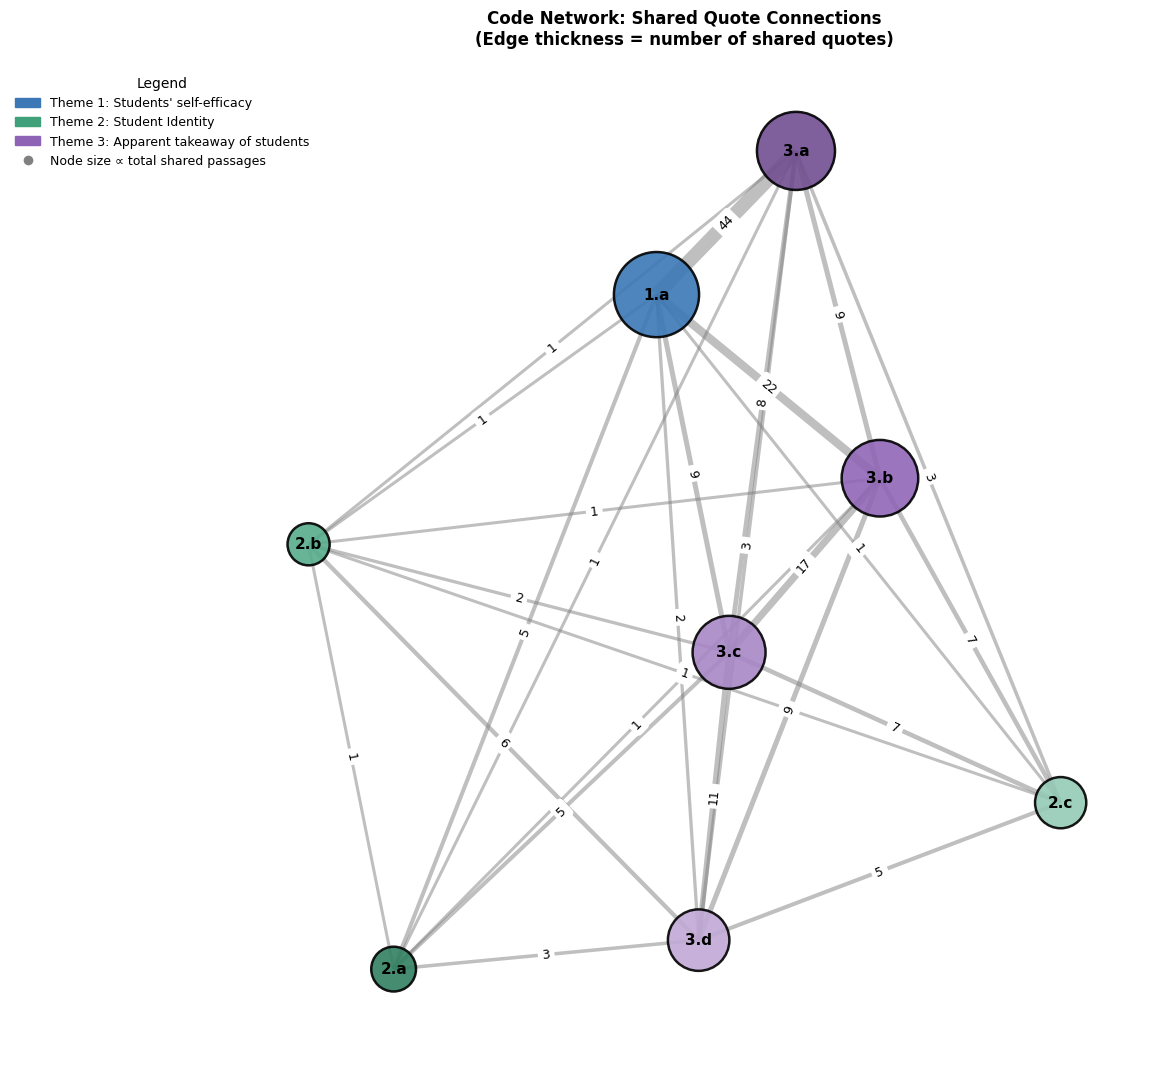


Code Network Statistics:
  Nodes (codes): 8
  Edges (co-occurrences): 27


In [22]:
# ------------------------------------------------------------------
# Build the code co-occurrence graph from aggregate_report.json
# Each entry in "within_interview_duplicates" is ONE passage of text that was
# coded more than once (several quote_ids, several codes).
# Edge weight = number of such passages that carry both codes.
# ------------------------------------------------------------------
dups = find_key(report_data, 'within_interview_duplicates') or {}

pair_passages = defaultdict(int)
for interview_id, entries in dups.items():
    for e in entries:
        codes = sorted(set(e.get('codes', [])))
        for a, b in combinations(codes, 2):
            pair_passages[(a, b)] += 1

G_overlap = nx.Graph()
for (a, b), w in pair_passages.items():
    G_overlap.add_edge(a, b, weight=w)
all_codes_list = sorted(G_overlap.nodes())

# Code network visualization with unified theme/code colours
if len(all_codes_list) > 0 and G_overlap.number_of_nodes() > 0:
    # Calculate code totals from co-occurrence
    code_total_quotes = {}
    for c in all_codes_list:
        if c in G_overlap:
            neighbors = list(G_overlap.neighbors(c))
            total = sum(G_overlap[c][nbr]['weight'] for nbr in neighbors) if neighbors else 0
            code_total_quotes[c] = total
        else:
            code_total_quotes[c] = 0

    # Node colours from the shared scheme (theme hue, code shade)
    node_colors = [code_color(c) for c in G_overlap.nodes()]
    node_sizes = [400 + code_total_quotes[c]*40 for c in G_overlap.nodes()]

    # Layout and draw
    pos_overlap = nx.spring_layout(G_overlap, k=2.2, iterations=100, seed=42)
    fig, ax = plt.subplots(figsize=(13, 11))

    nx.draw_networkx_nodes(G_overlap, pos_overlap, node_color=node_colors, node_size=node_sizes,
                           alpha=0.9, edgecolors='black', linewidths=1.8, ax=ax)

    weights_overlap = [G_overlap[u][v]['weight'] for u,v in G_overlap.edges()]
    max_w = max(weights_overlap) if weights_overlap else 1
    nx.draw_networkx_edges(G_overlap, pos_overlap, alpha=0.5, edge_color='gray',
                           width=[2+(w/max_w)*8 for w in weights_overlap], ax=ax)

    nx.draw_networkx_labels(G_overlap, pos_overlap, font_size=11, font_weight='bold', ax=ax)
    nx.draw_networkx_edge_labels(G_overlap, pos_overlap,
                                 {(u,v): int(G_overlap[u][v]['weight']) for u,v in G_overlap.edges()},
                                 font_size=9, ax=ax)

    # Legend
    handles = theme_legend_handles()
    handles.append(Line2D([0],[0], marker='o', color='w', markerfacecolor='gray', markersize=8,
                          label='Node size ∝ total shared passages'))
    ax.legend(handles=handles, loc='upper right', bbox_to_anchor=(0.1, 1.0), fontsize=9,
              title='Legend', frameon=False)
    ax.set_title('Code Network: Shared Quote Connections\n(Edge thickness = number of shared quotes)',
                 fontweight='bold', fontsize=12, pad=15)
    ax.axis('off')
    fig.subplots_adjust(left=0.02, right=0.72, top=0.92, bottom=0.02)
    plt.show()

    print("\nCode Network Statistics:")
    print(f"  Nodes (codes): {G_overlap.number_of_nodes()}")
    print(f"  Edges (co-occurrences): {G_overlap.number_of_edges()}")
else:
    print("Insufficient data for code network visualization")
